Loan Approval Project

In [60]:
import pandas as pd 

In [61]:
#import all the necessary libraries:
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder,OneHotEncoder,StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.metrics import classification_report,confusion_matrix,accuracy_score


In [62]:
#load the data:
df=pd.read_csv('loan_data (1).csv')

In [63]:
#to fetch the first 5 rows from the dataset:
df.head()

,person_age,person_gender,person_education,person_income,person_emp_exp,person_home_ownership,loan_amnt,loan_intent,loan_int_rate,loan_percent_income,cb_person_cred_hist_length,credit_score,previous_loan_defaults_on_file,loan_status
0,22.0,female,Master,71948.0,0,RENT,35000.0,PERSONAL,16.02,0.49,3.0,561,No,1
1,21.0,female,High School,12282.0,0,OWN,1000.0,EDUCATION,11.14,0.08,2.0,504,Yes,0
2,25.0,female,High School,12438.0,3,MORTGAGE,5500.0,MEDICAL,12.87,0.44,3.0,635,No,1
3,23.0,female,Bachelor,79753.0,0,RENT,35000.0,MEDICAL,15.23,0.44,2.0,675,No,1
4,24.0,male,Master,66135.0,1,RENT,35000.0,MEDICAL,14.27,0.53,4.0,586,No,1


In [64]:
#to fetch the botom 5 rows from the dataset:
df.tail()

,person_age,person_gender,person_education,person_income,person_emp_exp,person_home_ownership,loan_amnt,loan_intent,loan_int_rate,loan_percent_income,cb_person_cred_hist_length,credit_score,previous_loan_defaults_on_file,loan_status
44995,27.0,male,Associate,47971.0,6,RENT,15000.0,MEDICAL,15.66,0.31,3.0,645,No,1
44996,37.0,female,Associate,65800.0,17,RENT,9000.0,HOMEIMPROVEMENT,14.07,0.14,11.0,621,No,1
44997,33.0,male,Associate,56942.0,7,RENT,2771.0,DEBTCONSOLIDATION,10.02,0.05,10.0,668,No,1
44998,29.0,male,Bachelor,33164.0,4,RENT,12000.0,EDUCATION,13.23,0.36,6.0,604,No,1
44999,24.0,male,High School,51609.0,1,RENT,6665.0,DEBTCONSOLIDATION,17.05,0.13,3.0,628,No,1


In [65]:
#perform EDA(exploratory data analysis):
#to check all the information of the dataset:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 45000 entries, 0 to 44999
Data columns (total 14 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   person_age                      45000 non-null  float64
 1   person_gender                   45000 non-null  str    
 2   person_education                45000 non-null  str    
 3   person_income                   45000 non-null  float64
 4   person_emp_exp                  45000 non-null  int64  
 5   person_home_ownership           45000 non-null  str    
 6   loan_amnt                       45000 non-null  float64
 7   loan_intent                     45000 non-null  str    
 8   loan_int_rate                   45000 non-null  float64
 9   loan_percent_income             45000 non-null  float64
 10  cb_person_cred_hist_length      45000 non-null  float64
 11  credit_score                    45000 non-null  int64  
 12  previous_loan_defaults_on_file  45000 non-n

In [66]:
#to check for the nulls in the dataset:
df.isnull().sum()

person_age                        0
person_gender                     0
person_education                  0
person_income                     0
person_emp_exp                    0
person_home_ownership             0
loan_amnt                         0
loan_intent                       0
loan_int_rate                     0
loan_percent_income               0
cb_person_cred_hist_length        0
credit_score                      0
previous_loan_defaults_on_file    0
loan_status                       0
dtype: int64

In [67]:
#to check the duplicated rows in the dataset;
df[df.duplicated()]

,person_age,person_gender,person_education,person_income,person_emp_exp,person_home_ownership,loan_amnt,loan_intent,loan_int_rate,loan_percent_income,cb_person_cred_hist_length,credit_score,previous_loan_defaults_on_file,loan_status


In [68]:
#converting person_age into an integer format:
df['person_age']=df['person_age'].astype(int)

In [69]:
df['person_age']

0        22
1        21
2        25
3        23
4        24
         ..
44995    27
44996    37
44997    33
44998    29
44999    24
Name: person_age, Length: 45000, dtype: int64

In [70]:
#to understand the statistical information about the dataset:
df.describe()

,person_age,person_income,person_emp_exp,loan_amnt,loan_int_rate,loan_percent_income,cb_person_cred_hist_length,credit_score,loan_status
count,45000.000000,4.500000e+04,45000.000000,45000.000000,45000.000000,45000.000000,45000.000000,45000.000000,45000.000000
mean,27.764178,8.031905e+04,5.410333,9583.157556,11.006606,0.139725,5.867489,632.608756,0.222222
std,6.045108,8.042250e+04,6.063532,6314.886691,2.978808,0.087212,3.879702,50.435865,0.415744
min,20.000000,8.000000e+03,0.000000,500.000000,5.420000,0.000000,2.000000,390.000000,0.000000
25%,24.000000,4.720400e+04,1.000000,5000.000000,8.590000,0.070000,3.000000,601.000000,0.000000
50%,26.000000,6.704800e+04,4.000000,8000.000000,11.010000,0.120000,4.000000,640.000000,0.000000
75%,30.000000,9.578925e+04,8.000000,12237.250000,12.990000,0.190000,8.000000,670.000000,0.000000
max,144.000000,7.200766e+06,125.000000,35000.000000,20.000000,0.660000,30.000000,850.000000,1.000000


In [71]:
#to get the categorical data alone:
df.describe(include=object)

C:\Users\lenovo\AppData\Local\Temp\ipykernel_6848\2183220612.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include=object)


,person_gender,person_education,person_home_ownership,loan_intent,previous_loan_defaults_on_file
count,45000,45000,45000,45000,45000
unique,2,5,4,6,2
top,male,Bachelor,RENT,EDUCATION,Yes
freq,24841,13399,23443,9153,22858


In [72]:
#setting the age limit :
df = df[df['person_age'] <= 100]

<Axes: xlabel='loan_status', ylabel='count'>

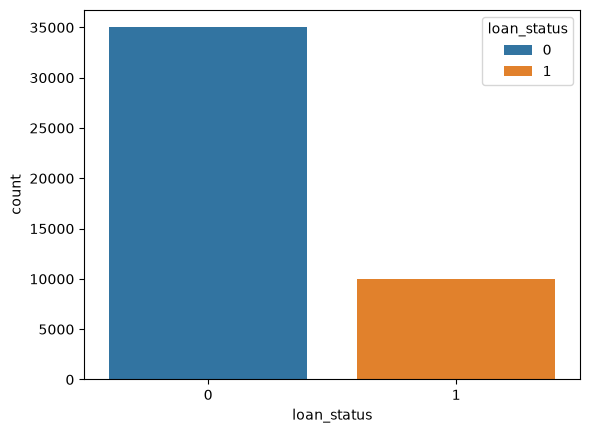

In [73]:
#to see the visualization:
sns.countplot(x='loan_status',data=df,hue='loan_status')

<Axes: xlabel='person_age', ylabel='Count'>

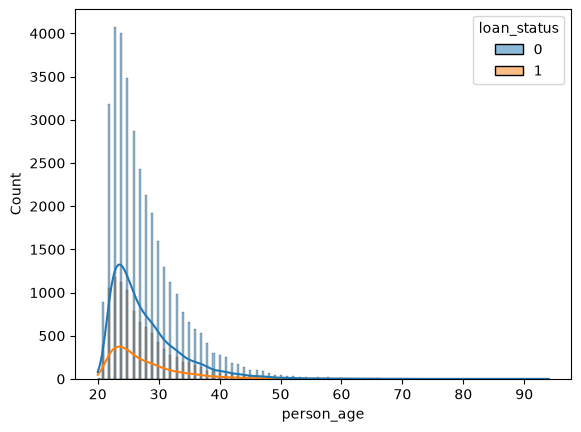

In [74]:
#to see the visualization using histplot:
sns.histplot(x='person_age',data=df,hue='loan_status',kde=True)

people who are born in 20 and 40 are applying for a loan 


<Axes: xlabel='loan_status', ylabel='person_age'>

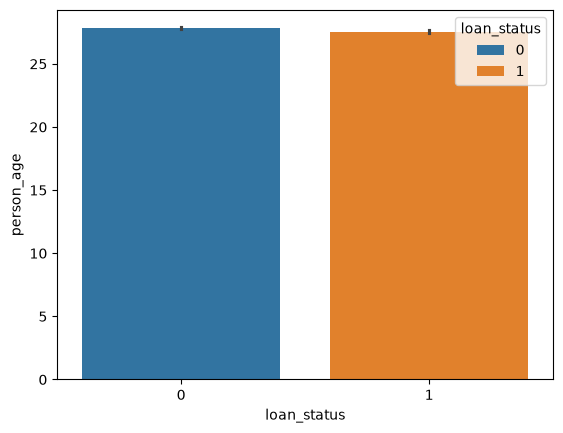

In [75]:
#to see the visualization using barplot:
sns.barplot(x='loan_status',y='person_age',data=df,hue='loan_status')

#multi model training at a same time:

In [76]:
#dividing the data into x and y :
x=df.drop('loan_status',axis=1)
y=df['loan_status']

In [77]:
#splitting the dataset into training and testing :
xtrain,xtest,ytrain,ytest=train_test_split(x,y,test_size=0.3,random_state=42)

In [78]:
#seperate numeric and object columns:
num_cols=xtrain.select_dtypes(include='number').columns
cat_cols=xtrain.select_dtypes(include='object').columns

C:\Users\lenovo\AppData\Local\Temp\ipykernel_6848\4032395840.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols=xtrain.select_dtypes(include='object').columns


In [79]:
#initializing all the models:

models = {"Logistic Regression":Pipeline([
                                ("preprocessor",ColumnTransformer([("scaler",StandardScaler(),num_cols),("encoder",OneHotEncoder(),cat_cols)])),
                                ("model",LogisticRegression(class_weight="balanced"))
                            ]),

            "Naive Bayes": Pipeline([
                            ("preprocessor",ColumnTransformer([("scaler",StandardScaler(),num_cols),("encoder",OneHotEncoder(),cat_cols)])),
                            ("model",GaussianNB())
                        ]),

            "SVM":Pipeline([
                    ("preprocessor",ColumnTransformer([("scaler",StandardScaler(),num_cols),("encoder",OneHotEncoder(),cat_cols)])),
                    ("model",SVC())
                ]),

            "Decision Tree": Pipeline([
                            ("preprocessor",ColumnTransformer([("scaler",StandardScaler(),num_cols),("encoder",OneHotEncoder(),cat_cols)])),
                            ("model",DecisionTreeClassifier(max_depth=6))
                        ]),

            "Random Forest":Pipeline([
                            ("preprocessor",ColumnTransformer([("scaler",StandardScaler(),num_cols),("encoder",OneHotEncoder(),cat_cols)])),
                            ("model",RandomForestClassifier(n_estimators=100,max_depth=6,random_state=42))
                        ])
          
          }

In [80]:
#train the multiple pipelines and save the accuracy:
model_perf={}
for model_name,pipeline in models.items():
    #train pipelines:
    pipeline.fit(xtrain,ytrain)
    #predictions:
    ypred=pipeline.predict(xtest)
    #accuracy:
    accuracy = accuracy_score(ytest,ypred)
    #save the model_metrics:
    model_perf[model_name]=accuracy


In [81]:
#Save the models:
perf_df = pd.Series(model_perf)
perf_df = pd.DataFrame(perf_df,columns=["accuracy"])
perf_df.to_csv("models_perf_dataset.csv")
perf_df

,accuracy
Logistic Regression,0.859164
Naive Bayes,0.743592
SVM,0.918432
Decision Tree,0.912431
Random Forest,0.917395


In [82]:
#fetch the best model and metrics:
best=max(model_perf.items(),key=lambda x :x[1])
print('best model:',best[0])
print('best model accuracy:',best[1])

best model: SVM
best model accuracy: 0.9184323603496815


In [83]:
#save the best pipeline model:
import pickle
best_pipeline=models[best[0]]
with open ('best_model_pipeline.pkl','wb') as file:
    pickle.dump(best_pipeline,file)
    print("Best model pipeline saved successfully")

Best model pipeline saved successfully


In [84]:
#predictions:
pipeline.predict(xtrain)

array([0, 0, 0, ..., 0, 0, 0], shape=(31495,))

In [85]:
#save cleaned pipeline 
df.to_csv("cleaned_data.csv")

In [86]:
xtrain.columns

Index(['person_age', 'person_gender', 'person_education', 'person_income',
       'person_emp_exp', 'person_home_ownership', 'loan_amnt', 'loan_intent',
       'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length',
       'credit_score', 'previous_loan_defaults_on_file'],
      dtype='str')

In [87]:
df['person_age'].unique()

array([22, 21, 25, 23, 24, 26, 20, 32, 34, 29, 33, 28, 35, 31, 27, 30, 36,
       40, 50, 45, 37, 39, 44, 43, 41, 46, 38, 47, 42, 48, 49, 58, 65, 51,
       53, 66, 61, 54, 57, 59, 62, 60, 55, 52, 64, 70, 78, 69, 56, 73, 63,
       94, 80, 84, 76, 67])

In [88]:
df['person_age'].min(), df['person_age'].max()

(np.int64(20), np.int64(94))

In [90]:
df['person_income'].describe()

count    4.499300e+04
mean     7.990845e+04
std      6.332213e+04
min      8.000000e+03
25%      4.719500e+04
50%      6.704600e+04
75%      9.577800e+04
max      2.448661e+06
Name: person_income, dtype: float64

In [91]:
df['loan_amnt'].describe()

count    44993.000000
mean      9583.176761
std       6314.802655
min        500.000000
25%       5000.000000
50%       8000.000000
75%      12237.000000
max      35000.000000
Name: loan_amnt, dtype: float64